ACTIVITY 1

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

np.random.seed(42)

# Create data for 3 conceptual groups
small_animals = np.random.normal(
    loc=[5, 20], scale=[1, 5], size=(20, 2)
)

medium_animals = np.random.normal(
    loc=[50, 80], scale=[10, 15], size=(20, 2)
)

large_animals = np.random.normal(
    loc=[300, 150], scale=[50, 25], size=(20, 2)
)

# Combine all animal data
X_animals = pd.DataFrame(
    np.vstack([             #vertical stacking
        small_animals,
        medium_animals,
        large_animals
    ]),
    columns=['Weight_kg', 'Height_cm']
)

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_animals)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X_animals.columns
)

print("Scaled Animal Data (first 5 rows):")
print(X_scaled_df.head())

Scaled Animal Data (first 5 rows):
   Weight_kg  Height_cm
0  -0.846383  -1.148828
1  -0.845239  -1.001016
2  -0.851919  -1.157358
3  -0.838182  -1.068244
4  -0.853702  -1.088252


In [ ]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model to scaled data
kmeans.fit(X_scaled_df)

# Get cluster labels
labels = kmeans.labels_

# Add cluster labels to original dataset
X_animals['Cluster'] = labels

# Display results
print("Animal Data with Cluster Labels:")
print(X_animals.head(10))

# Display cluster centroids
print("\nCluster Centroids (Scaled Data):")
print(kmeans.cluster_centers_)

Animal Data with Cluster Labels:
   Weight_kg  Height_cm  Cluster
0   5.496714  19.308678        2
1   5.647689  27.615149        2
2   4.765847  18.829315        2
3   6.579213  23.837174        2
4   4.530526  22.712800        2
5   4.536582  17.671351        2
6   5.241962  10.433599        2
7   3.275082  17.188562        2
8   3.987169  21.571237        2
9   4.091976  12.938481        2

Cluster Centroids (Scaled Data):
[[-0.52213772 -0.03895372]
 [ 1.37361708  1.19871673]
 [-0.85147936 -1.15976301]]


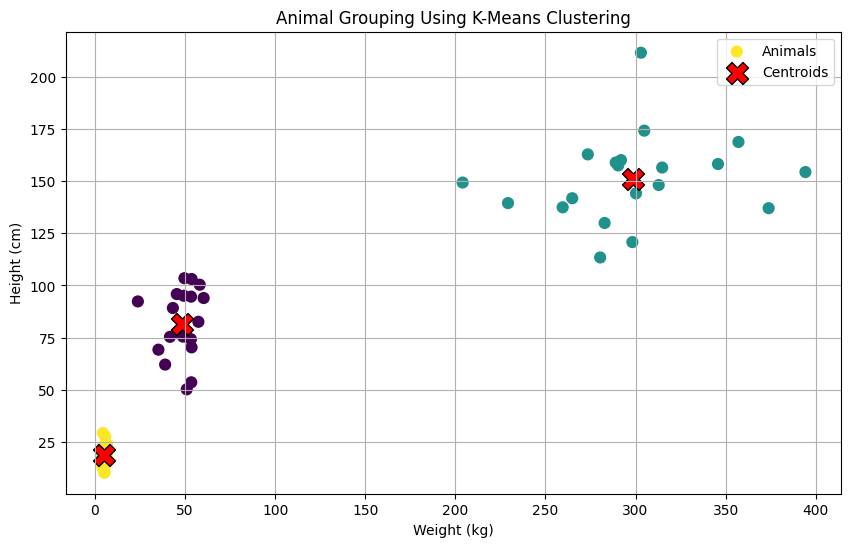

In [ ]:
# Get centroids in original scale
centroids = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Plot animal clusters
plt.figure(figsize=(10, 6))

plt.scatter(
    X_animals['Weight_kg'],
    X_animals['Height_cm'],
    c=X_animals['Cluster'],
    cmap='viridis',
    s=60,
    label='Animals'
)

# Plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=250,
    edgecolors='black',
    label='Centroids'
)

plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title('Animal Grouping Using K-Means Clustering')

plt.legend()
plt.grid(True)
plt.show()

ACTVITY 2

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

np.random.seed(42)

# Create synthetic student data
X_students = pd.DataFrame({
    'Study_Hours_Week': np.random.randint(5, 40, 50),
    'Sleep_Hours_Night': np.random.uniform(4, 9, 50).round(1)
})

# High study hours and low sleep
X_students.loc[
    X_students['Study_Hours_Week'] > 30,
    'Sleep_Hours_Night'
] = np.random.uniform(
    4, 6,
    sum(X_students['Study_Hours_Week'] > 30)
).round(1)

# Low study hours and high sleep
X_students.loc[
    X_students['Study_Hours_Week'] < 10,
    'Sleep_Hours_Night'
] = np.random.uniform(
    7, 9,
    sum(X_students['Study_Hours_Week'] < 10)
).round(1)

# Display first five rows
print("\nStudent Habit Data (first 5 rows):\n")
print(X_students.head())


Student Habit Data (first 5 rows):

   Study_Hours_Week  Sleep_Hours_Night
0                33                5.0
1                19                6.0
2                12                8.6
3                25                7.6
4                23                5.6


In [ ]:
# Perform hierarchical clustering using Ward method
Z = linkage(X_students, method='ward')

# Display linkage results
print("Hierarchical Clustering Results:\n")
print(Z)

Hierarchical Clustering Results:

[[10.         25.          0.          2.        ]
 [22.         37.          0.1         2.        ]
 [43.         46.          0.1         2.        ]
 [35.         44.          0.2         2.        ]
 [30.         52.          0.28867513  3.        ]
 [ 3.         27.          0.3         2.        ]
 [ 2.         39.          0.3         2.        ]
 [12.         15.          0.4         2.        ]
 [ 8.          9.          0.5         2.        ]
 [ 0.         47.          0.9         2.        ]
 [11.         19.          0.9         2.        ]
 [20.         31.          1.          2.        ]
 [ 1.         32.          1.00498756  2.        ]
 [ 5.         13.          1.00498756  2.        ]
 [ 4.         36.          1.0198039   2.        ]
 [42.         48.          1.0198039   2.        ]
 [24.         41.          1.07703296  2.        ]
 [ 6.         18.          1.11803399  2.        ]
 [28.         56.          1.16761866  3.       

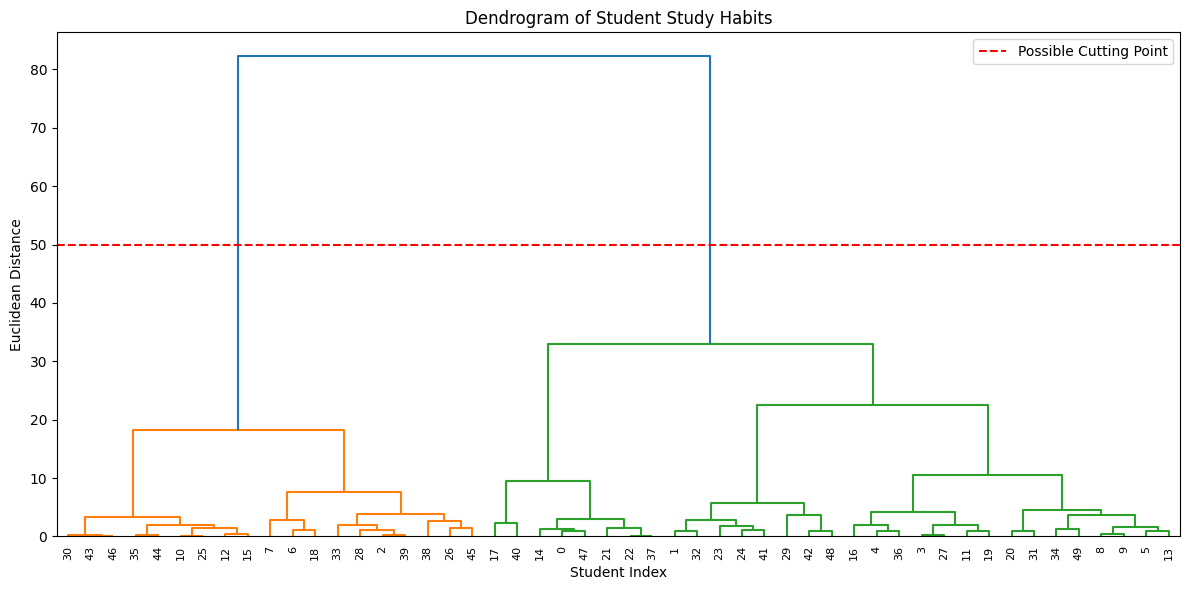

In [ ]:
# Generate dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    labels=X_students.index,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Dendrogram of Student Study Habits")
plt.xlabel("Student Index")
plt.ylabel("Euclidean Distance")
plt.axhline(y=50, color='red', linestyle='--',
            label='Possible Cutting Point')

plt.legend()
plt.tight_layout()
plt.show()